In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import LOB

In [2]:
import torch 

torch.cuda.is_available()

False

In [3]:
# !pip install torch
# !pip install cupy
# !pip install scikit-learn

In [4]:
import sys
#sys.path.insert(0, "/cygdrive/c/Users/Dell/OneDrive/Documents/TomDocuments/PythonProjects/PP/20261102/PatnaikPearson/PatnaikPearson")      # the folder containing the modules
sys.path.insert(0, "../../../PP/20261102/PatnaikPearson") 
import PatnaikPearson as pp

In [5]:
message_file = 'Data/AAPL_2026-03-04_34140000_57660000_message_10.csv' 
orderbook_file='Data/AAPL_2026-03-04_34140000_57660000_orderbook_10.csv'

In [6]:
use_price_diffs_z_scores = True # good
use_cum_size_z_scores = True # good
use_log_cum_size_z_scores = True
use_ob_imbalance = True
use_ob_imbalance_z_scores = True
use_ob_log_imbalance = True
use_ob_log_imbalance_z_scores = True
use_total_size_z_scores = True
use_log_total_size_z_scores = True
lookback = 201

min_index = 30000
max_index = min_index + 20000

orderbook_depth = 2

df_rep = LOB.create_representation_one(orderbook_file, 
                                       message_file,
                                       use_price_diffs_z_scores, 
                                       use_cum_size_z_scores, 
                                       use_log_cum_size_z_scores, 
                                       use_ob_imbalance, 
                                       use_ob_imbalance_z_scores, 
                                       use_ob_log_imbalance, 
                                       use_ob_log_imbalance_z_scores, 
                                       use_total_size_z_scores,
                                       use_log_total_size_z_scores,
                                       lookback, 
                                       min_index, 
                                       max_index,
                                       orderbook_depth)

In [7]:
sep = "="*80
print(df_rep.head(2))
print(sep)
print(df_rep.tail(2))

             Time  AP2_minus_AP1_z  BP2_minus_BP1_z  AP1_minus_BP1_z  \
201  34228.387884        -0.309592        -0.901659        -0.010174   
202  34228.387919        -0.305726        -0.883108        -0.010058   

     BP1_minus_AP1_z  AP2_minus_BP1_z  BP2_minus_AP1_z  cum_AskSize_1_1_z  \
201         0.010174        -0.105052        -0.837479          -1.088890   
202         0.010058        -0.103842        -0.821292          -1.061995   

     cum_BidSize_1_1_z  cum_AskSize_1_2_z  ...  \
201           0.823192          -1.213853  ...   
202           0.807499          -1.180048  ...   

     cum_BidSize_minus_AskSize_1_2_z  cum_BidSize_minus_AskSize_1_2_z  \
201                         1.375734                         0.887027   
202                         1.331182                         0.869035   

     cum_BidSize_plus_AskSize_1_1_z  cum_BidSize_plus_AskSize_1_1_z  \
201                        0.258666                        0.461467   
202                        0.255521   

In [8]:
print(df_rep.shape)
#print(df_rep.columns)
num_nans = np.count_nonzero(np.isnan(df_rep))
print("num_nans = ", num_nans)

(19798, 39)
num_nans =  0


In [9]:
N = 500
i = N

X = df_rep.iloc[-N:].to_numpy()
print(X.shape)
num_nans = np.count_nonzero(np.isnan(X))
print("num_nans = ", num_nans)
pp.display_stats(X)
pp_dim_X = pp.calculate_PatnaikPearson_dim(X)
print("PP(X) = ", pp_dim_X)

(500, 39)
num_nans =  0
shape : (500, 39)
min : -6.483948343282178
max : 34307.519194801
sum : 17155053.935683556
mean : 879.7463556760798
std : 5422.466838583184
** calculate_nu_cpu ** running on CPU
PP(X) =  9.780599457711164


In [10]:
stride = 100
N = 500
i_vals = []
t_vals = []
pp_dim_X_vals = []
pp_dim_X_over_dim_X_vals = []

for i in np.arange(N, df_rep.shape[0], stride):
    i_vals.append(i)
    t_vals.append(df_rep["Time"][i])
    X = df_rep.iloc[i - N : i].to_numpy()
    pp_dim_X = pp.calculate_PatnaikPearson_dim(X)
    pp_dim_X_vals.append(pp_dim_X)
    dim_X = X.shape[1]
    pp_dim_X_over_dim_X_vals.append(pp_dim_X / dim_X)
    print(i, pp_dim_X)

** calculate_nu_cpu ** running on CPU
500 9.332689711883898
** calculate_nu_cpu ** running on CPU
600 9.977722007718015
** calculate_nu_cpu ** running on CPU
700 10.225108980229638
** calculate_nu_cpu ** running on CPU
800 10.216722579264717
** calculate_nu_cpu ** running on CPU
900 10.492623434448653
** calculate_nu_cpu ** running on CPU
1000 10.791192578378505
** calculate_nu_cpu ** running on CPU
1100 10.572572004561675
** calculate_nu_cpu ** running on CPU
1200 10.093257860824258
** calculate_nu_cpu ** running on CPU
1300 10.239578423574356
** calculate_nu_cpu ** running on CPU
1400 9.567908308077003
** calculate_nu_cpu ** running on CPU
1500 9.074693036491503
** calculate_nu_cpu ** running on CPU
1600 10.184842434393925
** calculate_nu_cpu ** running on CPU
1700 10.600011116030203
** calculate_nu_cpu ** running on CPU
1800 10.447965114423452
** calculate_nu_cpu ** running on CPU
1900 10.455398526488418
** calculate_nu_cpu ** running on CPU
2000 10.610037379820248
** calculate_nu_c

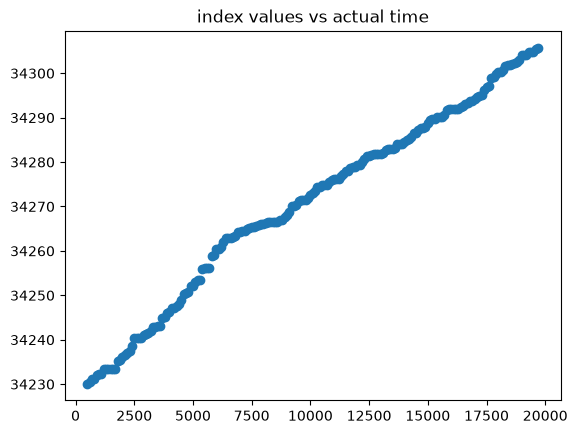

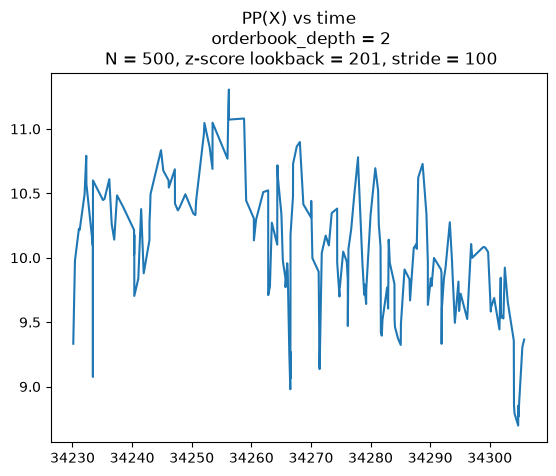

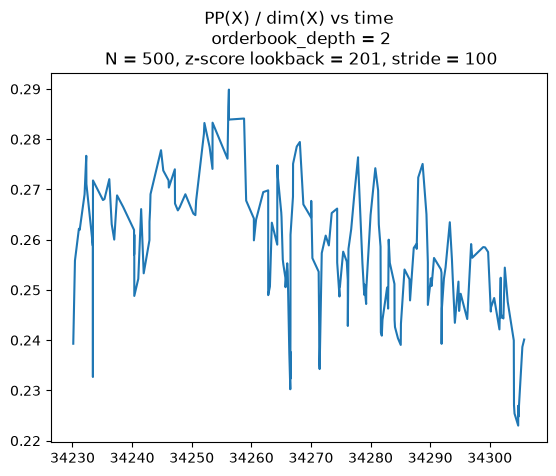

In [11]:
title_suffix = "\n orderbook_depth = " + str(orderbook_depth)
title_suffix += "\n N = " + str(N) 
title_suffix += ", z-score lookback = " + str(lookback)
title_suffix += ", stride = " + str(stride)

plt.scatter(i_vals, t_vals)
#plt.plot(i_vals, i_vals, color="red", linestyle="--")
plt.title("index values vs actual time")
plt.show()

this_title = "PP(X) vs time" + title_suffix
plt.plot(t_vals, pp_dim_X_vals)
plt.title(this_title)
plt.show()

this_title = "PP(X) / dim(X) vs time" + title_suffix
plt.plot(t_vals, pp_dim_X_over_dim_X_vals)
plt.title(this_title)
plt.show()